# **Understanding the Problem Behind UNSW-NB15**

**UNSW-NB15** = A network intrusion-detection dataset created by UNSW (University of New South Wales).



### **Imagine you are monitoring a company's network.**

Computers are constantly communicating:

Computer A  ---------->  Server B  
Laptop      ---------->  Website  
Server      ---------->  Database  

Every communication generates network traffic.

For example:

| Feature | Value |
|----------|----------|
| Source IP | 192.168.1.10 |
| Destination IP | 10.20.30.5 |
| Protocol | TCP |
| Duration | 2.3 seconds |
| Bytes Sent | 1500 |
| Bytes Received | 8200 |
| Packets Sent | 12 |
| Packets Received | 18 |

---

Now imagine an attacker starts doing something suspicious.

#### ***The traffic might look different:***

Huge number of packets  
        ↓  
Many destinations  
        ↓  
Unusual ports  
        ↓  
Unusual packet sizes  
        ↓  
Unusual connection behavior  

---

The central question becomes:

### **Can we use the characteristics of network traffic to determine whether that traffic is normal or malicious?**

That is the fundamental problem behind the **UNSW-NB15 dataset**.

The UNSW-NB15 dataset contains network traffic records represented by various features such as source and destination information, protocol details, packet statistics, and connection characteristics. Each record is labeled as either **normal** or **malicious**, enabling researchers and practitioners to develop machine learning models that can automatically detect cyber attacks and improve network security.

# **1) Dataset Audit**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [9]:
# Loading the dataset
df_train = pd.read_parquet("../dataset/train_full.parquet")
df_test = pd.read_parquet("../dataset/test_full.parquet")

pd.set_option('display.max_columns', None)

* **Training Dataset:** Total No. of columns: `~1.75 lakhs` and total no. of rows: `45`
* **Testing Dataset:** Total No. of columns: `~82 thousand` and total no. of rows: `45`

In [10]:
df_train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


In [11]:
df_test.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0


In [12]:
# Count of Normal (0) vs Attack (1)
print("Count of label in taining data: \n" , df_train['label'].value_counts(), "\n")
print("Count of label in testing data: \n" ,df_test['label'].value_counts())

Count of label in taining data: 
 label
1    119341
0     56000
Name: count, dtype: int64 

Count of label in testing data: 
 label
1    45332
0    37000
Name: count, dtype: int64


It can be observed that the training dataset is imbalances as the count of normal attack is only `56000` but the cout of suspecious attack is `119341`. But, the testing data is well balanced.

In [13]:
# Count of Attack category
print(df_train['attack_cat'].value_counts(), "\n")
print(df_test['attack_cat'].value_counts())

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64 

attack_cat
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


In [14]:
# checking for null values

if df_train.isnull().sum().sum() > 0:
  print("There are null values in the training data.")
else:
  print("No null values in the training data.")

if df_test.isnull().sum().sum() > 0:
  print("There are null values in the testing data.")
else:
  print("No null values in the testing data.")

No null values in the training data.
No null values in the testing data.


In [15]:
# checking for duplicate rows
print("Duplicated Vlaue in Train data: ", df_train.duplicated().sum())
print("Duplicated Vlaue in Test data: ", df_test.duplicated().sum())

Duplicated Vlaue in Train data:  0
Duplicated Vlaue in Test data:  0


In [16]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

# **2) EDA**

### **1) How much of the traffic is malicious?**

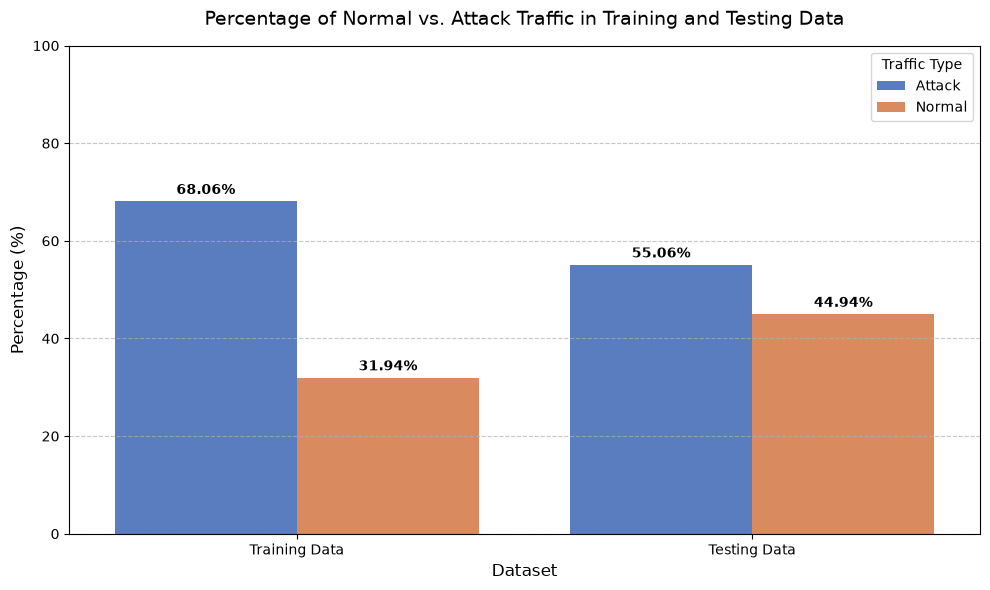

In [17]:
# Calculate percentages for Train dataset
train_counts = df_train['label'].value_counts(normalize=True).rename({0: 'Normal', 1: 'Attack'}).reset_index()
train_counts['percentage'] = train_counts['proportion'] * 100
train_counts['Dataset'] = 'Training Data'

# Calculate percentages for Test dataset
test_counts = df_test['label'].value_counts(normalize=True).rename({0: 'Normal', 1: 'Attack'}).reset_index()
test_counts['percentage'] = test_counts['proportion'] * 100
test_counts['Dataset'] = 'Testing Data'

# Combine data
combined_pcts = pd.concat([train_counts, test_counts], ignore_index=True)

# Plotting
plt.figure(figsize=(10, 6))
sns.barplot(x='Dataset', y='percentage', hue='label', data=combined_pcts, palette='muted')
plt.title('Percentage of Normal vs. Attack Traffic in Training and Testing Data', fontsize=14, pad=15)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xlabel('Dataset', fontsize=12)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Traffic Type')

# Add percentage labels on top of the bars
ax = plt.gca()
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontweight='bold')

plt.tight_layout()
plt.show()

### **2) Which attacks are most common?**

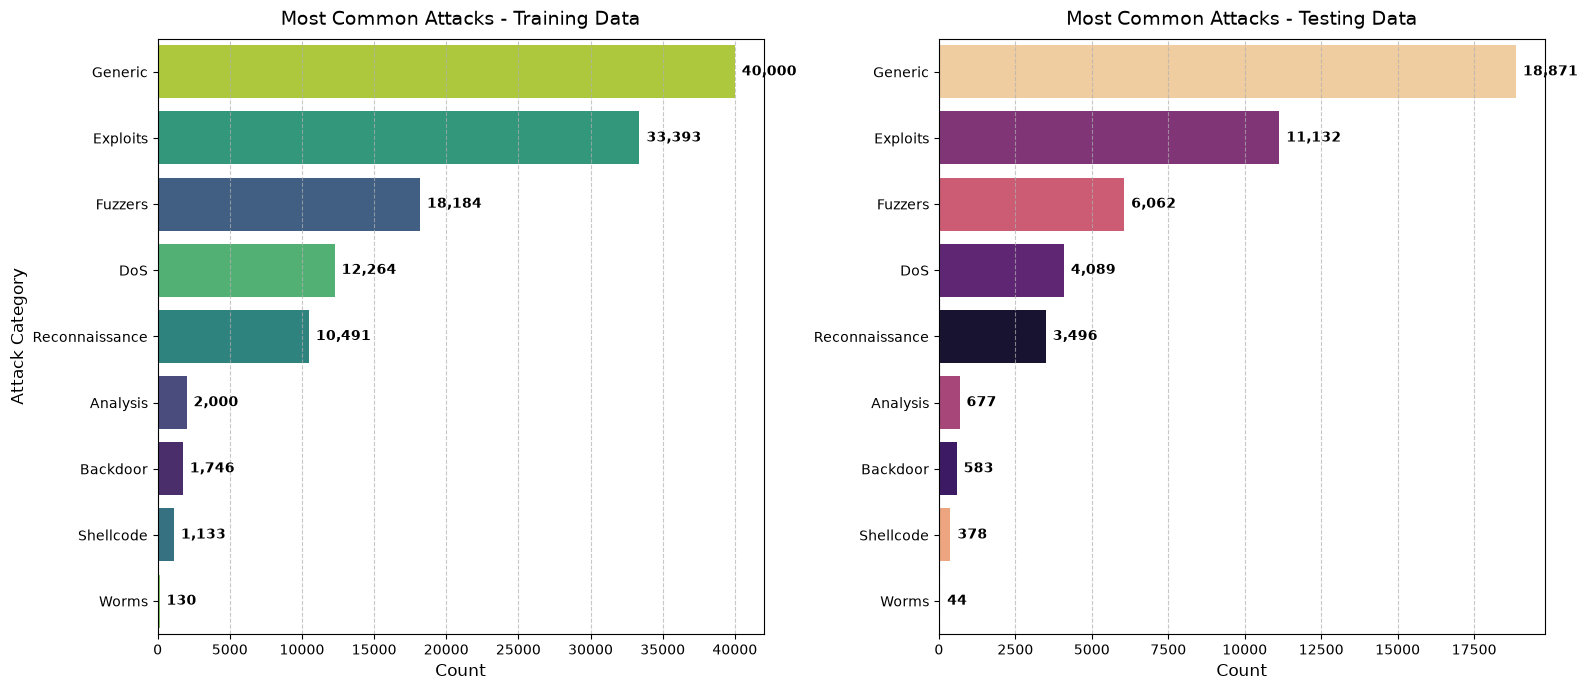

In [18]:
# Filter out 'Normal' records to analyze actual attack categories
train_attacks = df_train[df_train['attack_cat'] != 'Normal']
test_attacks = df_test[df_test['attack_cat'] != 'Normal']

# Get attack counts and order them by training set popularity
attack_order = train_attacks['attack_cat'].value_counts().index

# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=False)

# Plot Training Attack Categories
sns.countplot(
    y='attack_cat',
    data=train_attacks,
    order=attack_order,
    ax=axes[0],
    palette='viridis',
    hue='attack_cat',
    legend=False
)
axes[0].set_title('Most Common Attacks - Training Data', fontsize=14, pad=10)
axes[0].set_xlabel('Count', fontsize=12)
axes[0].set_ylabel('Attack Category', fontsize=12)
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

# Add count labels on the bars for Training Data
for p in axes[0].patches:
    width = p.get_width()
    if width > 0:
        axes[0].annotate(f"{int(width):,}",
                         (width, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center',
                         xytext=(5, 0),
                         textcoords='offset points',
                         fontweight='bold')

# Plot Testing Attack Categories
sns.countplot(
    y='attack_cat',
    data=test_attacks,
    order=attack_order,
    ax=axes[1],
    palette='magma',
    hue='attack_cat',
    legend=False
)
axes[1].set_title('Most Common Attacks - Testing Data', fontsize=14, pad=10)
axes[1].set_xlabel('Count', fontsize=12)
axes[1].set_ylabel('', fontsize=12)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

# Add count labels on the bars for Testing Data
for p in axes[1].patches:
    width = p.get_width()
    if width > 0:
        axes[1].annotate(f"{int(width):,}",
                         (width, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center',
                         xytext=(5, 0),
                         textcoords='offset points',
                         fontweight='bold')

plt.tight_layout()
plt.show()

### **3) Which protocols are associated with attacks?**

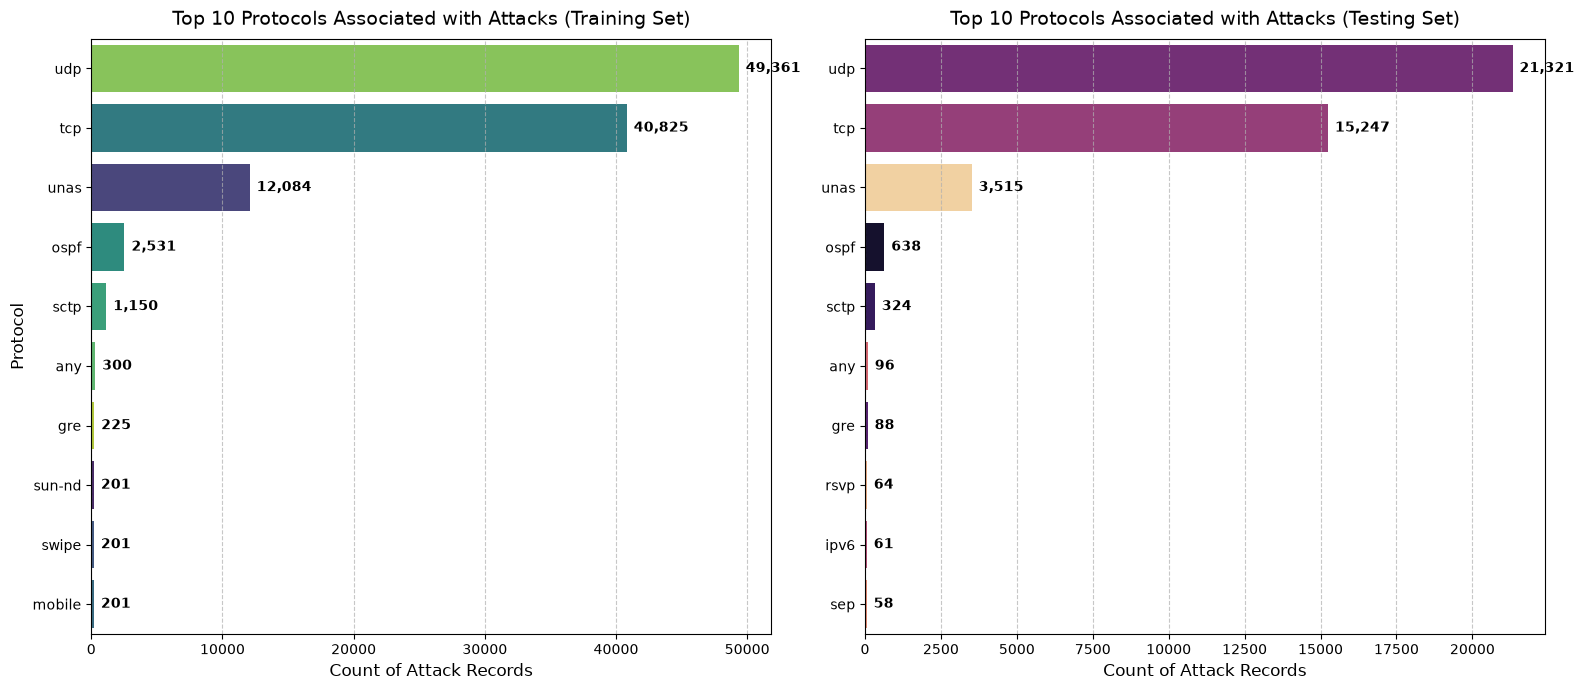

In [19]:
# Filter to keep only malicious (attack) traffic
train_attacks_proto = df_train[df_train['label'] == 1]
test_attacks_proto = df_test[df_test['label'] == 1]

# Get top 10 protocols associated with attacks
top_train_proto = train_attacks_proto['proto'].value_counts().head(10).index
top_test_proto = test_attacks_proto['proto'].value_counts().head(10).index

# Create side-by-side bar plots
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Training Data Plot
sns.countplot(
    y='proto',
    data=train_attacks_proto[train_attacks_proto['proto'].isin(top_train_proto)],
    order=top_train_proto,
    ax=axes[0],
    palette='viridis',
    hue='proto',
    legend=False
)
axes[0].set_title('Top 10 Protocols Associated with Attacks (Training Set)', fontsize=14, pad=10)
axes[0].set_xlabel('Count of Attack Records', fontsize=12)
axes[0].set_ylabel('Protocol', fontsize=12)
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

# Add counts labels on bars for Training Data
for p in axes[0].patches:
    width = p.get_width()
    if width > 0:
        axes[0].annotate(f"{int(width):,}",
                         (width, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center',
                         xytext=(5, 0),
                         textcoords='offset points',
                         fontweight='bold')

# Testing Data Plot
sns.countplot(
    y='proto',
    data=test_attacks_proto[test_attacks_proto['proto'].isin(top_test_proto)],
    order=top_test_proto,
    ax=axes[1],
    palette='magma',
    hue='proto',
    legend=False
)
axes[1].set_title('Top 10 Protocols Associated with Attacks (Testing Set)', fontsize=14, pad=10)
axes[1].set_xlabel('Count of Attack Records', fontsize=12)
axes[1].set_ylabel('', fontsize=12)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

# Add counts labels on bars for Testing Data
for p in axes[1].patches:
    width = p.get_width()
    if width > 0:
        axes[1].annotate(f"{int(width):,}",
                         (width, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center',
                         xytext=(5, 0),
                         textcoords='offset points',
                         fontweight='bold')

plt.tight_layout()
plt.show()

### **4) Do attack traffic and normal traffic behave differently?**

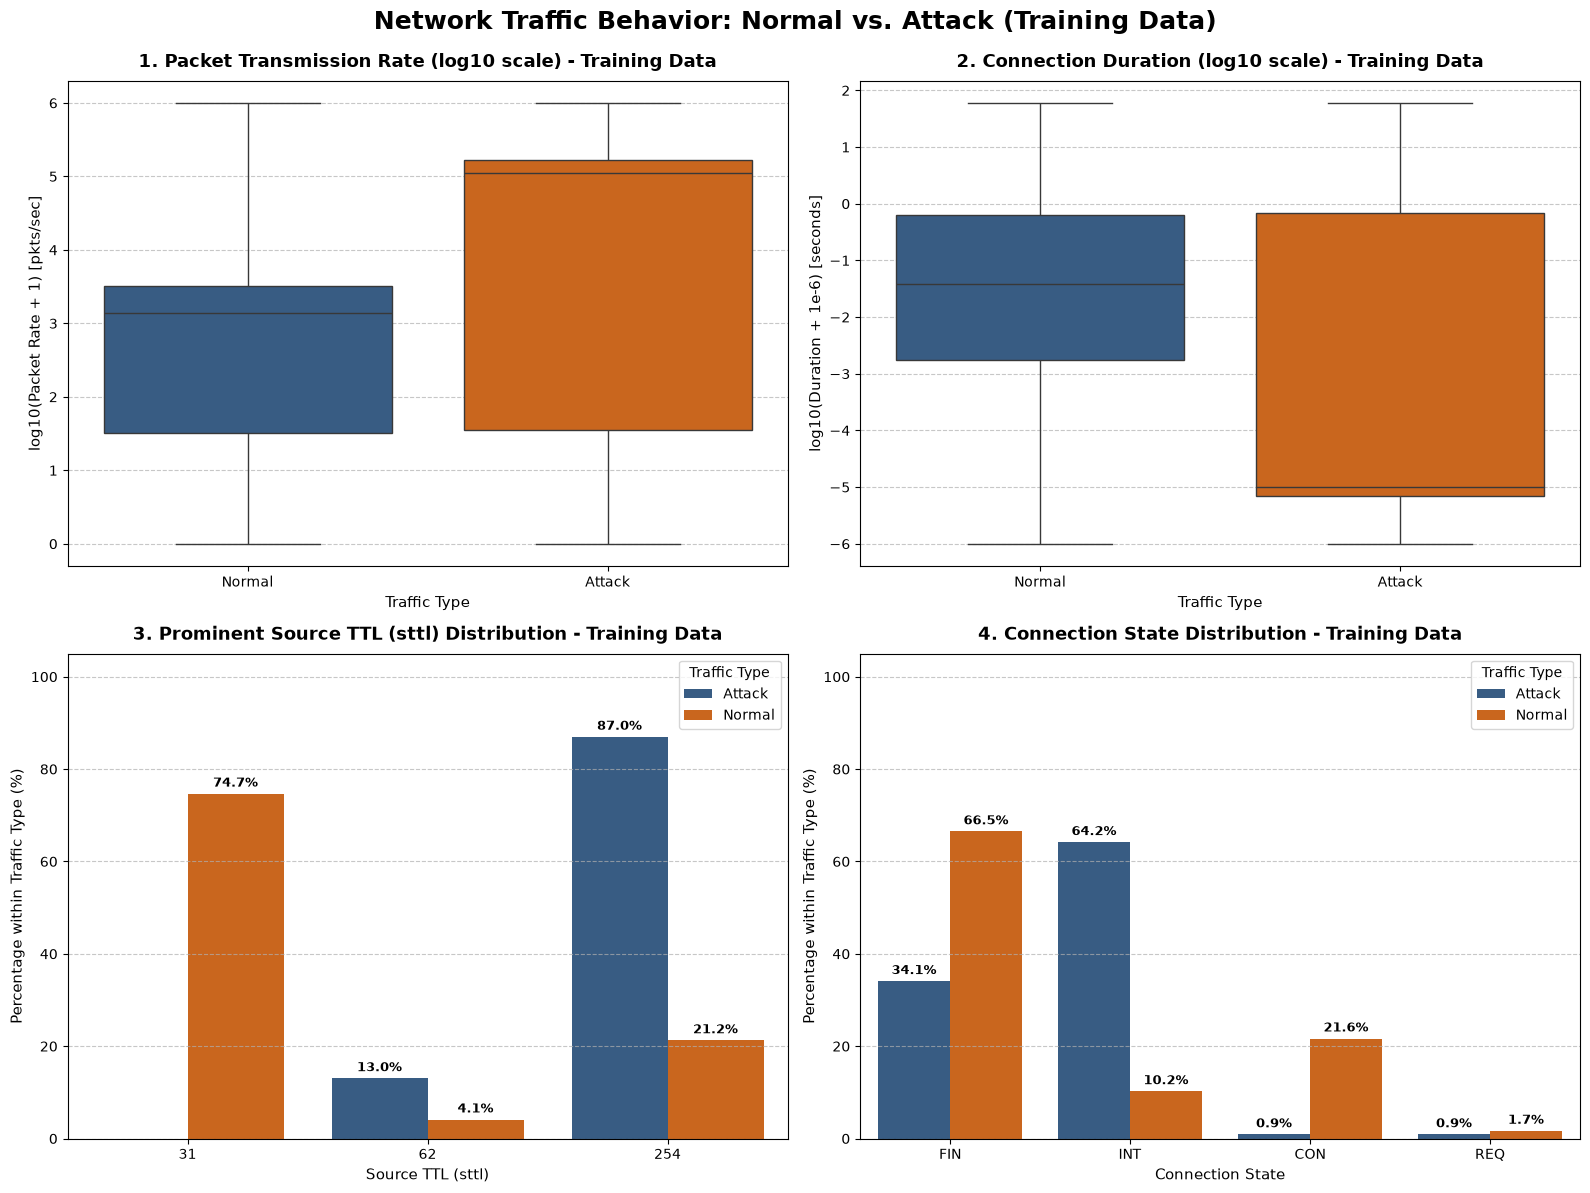

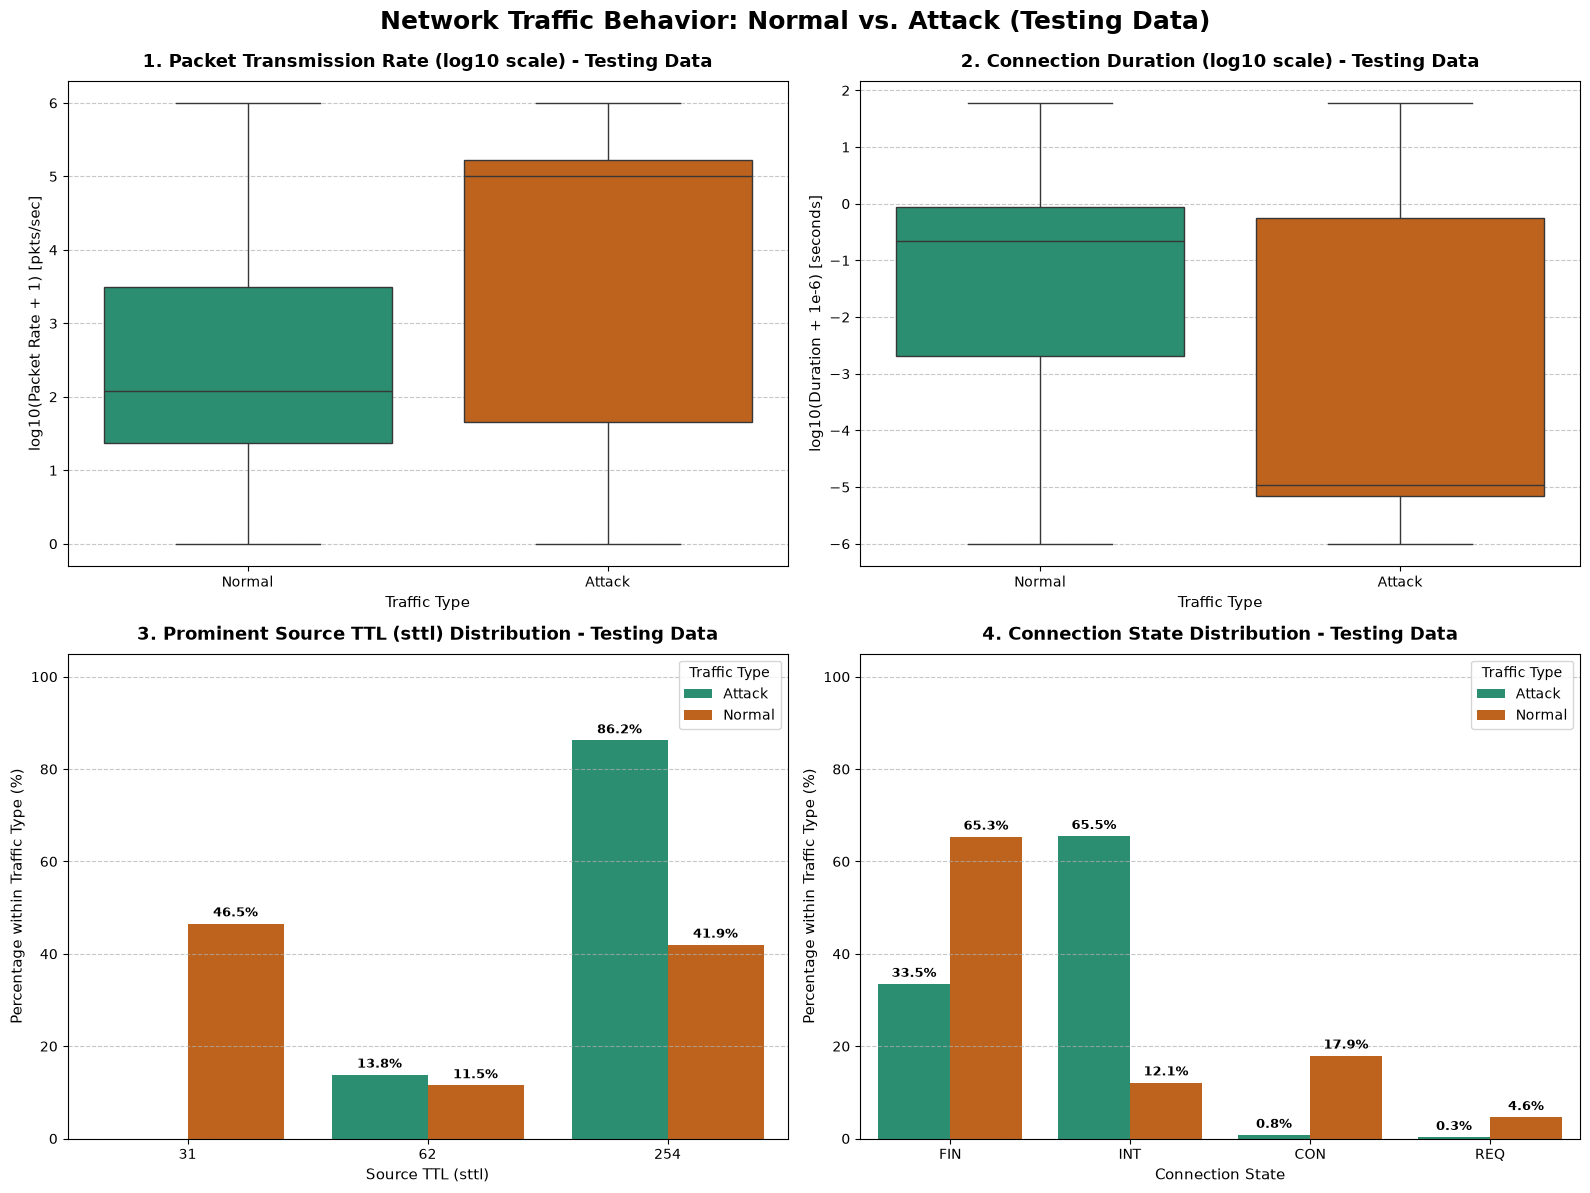

In [20]:
# Create traffic_type column for human-readable labels
df_train['traffic_type'] = df_train['label'].map({0: 'Normal', 1: 'Attack'})
df_test['traffic_type'] = df_test['label'].map({0: 'Normal', 1: 'Attack'})

def plot_traffic_behavior(df, dataset_name, palette):
    """
    Plots a 4-panel behavioral profile comparing Normal vs Attack traffic:
    1. Packet Transmission Rate (log10 scale)
    2. Connection Duration (log10 scale)
    3. Source TTL (sttl) Distribution
    4. Connection State Distribution
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f'Network Traffic Behavior: Normal vs. Attack ({dataset_name})', 
                 fontsize=18, fontweight='bold', y=0.99)
    
    # 1. Packet Transmission Rate (log10 scale)
    sns.boxplot(
        x='traffic_type',
        y=np.log10(df['rate'] + 1),
        data=df,
        ax=axes[0, 0],
        palette=palette,
        hue='traffic_type',
        legend=False
    )
    axes[0, 0].set_title(f'1. Packet Transmission Rate (log10 scale) - {dataset_name}', fontsize=13, fontweight='bold', pad=10)
    axes[0, 0].set_xlabel('Traffic Type', fontsize=11)
    axes[0, 0].set_ylabel('log10(Packet Rate + 1) [pkts/sec]', fontsize=11)
    axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)
    
    # 2. Connection Duration (log10 scale)
    sns.boxplot(
        x='traffic_type',
        y=np.log10(df['dur'] + 1e-6),
        data=df,
        ax=axes[0, 1],
        palette=palette,
        hue='traffic_type',
        legend=False
    )
    axes[0, 1].set_title(f'2. Connection Duration (log10 scale) - {dataset_name}', fontsize=13, fontweight='bold', pad=10)
    axes[0, 1].set_xlabel('Traffic Type', fontsize=11)
    axes[0, 1].set_ylabel('log10(Duration + 1e-6) [seconds]', fontsize=11)
    axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

    # 3. Source Time-To-Live (sttl) Distribution
    top_sttls = [31, 62, 254]
    sttl_df = df[df['sttl'].isin(top_sttls)]
    sttl_pct = (pd.crosstab(sttl_df['sttl'], sttl_df['traffic_type'], normalize='columns') * 100)
    sttl_plot_data = sttl_pct.loc[top_sttls].reset_index().melt(
        id_vars='sttl', value_name='Percentage', var_name='Traffic Type'
    )
    
    sns.barplot(
        x='sttl',
        y='Percentage',
        hue='Traffic Type',
        data=sttl_plot_data,
        ax=axes[1, 0],
        palette=palette
    )
    axes[1, 0].set_title(f'3. Prominent Source TTL (sttl) Distribution - {dataset_name}', fontsize=13, fontweight='bold', pad=10)
    axes[1, 0].set_xlabel('Source TTL (sttl)', fontsize=11)
    axes[1, 0].set_ylabel('Percentage within Traffic Type (%)', fontsize=11)
    axes[1, 0].set_ylim(0, 105)
    axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)
    axes[1, 0].legend(title='Traffic Type')
    for p in axes[1, 0].patches:
        h = p.get_height()
        if h > 0:
            axes[1, 0].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                                ha='center', va='bottom', xytext=(0, 3),
                                textcoords='offset points', fontsize=9, fontweight='bold')

    # 4. Connection State Distribution
    top_states = ['FIN', 'INT', 'CON', 'REQ']
    state_df = df[df['state'].isin(top_states)]
    state_pct = (pd.crosstab(state_df['state'], state_df['traffic_type'], normalize='columns') * 100)
    state_plot_data = state_pct.reindex(top_states).fillna(0).reset_index().melt(
        id_vars='state', value_name='Percentage', var_name='Traffic Type'
    )
    
    sns.barplot(
        x='state',
        y='Percentage',
        hue='Traffic Type',
        data=state_plot_data,
        ax=axes[1, 1],
        palette=palette
    )
    axes[1, 1].set_title(f'4. Connection State Distribution - {dataset_name}', fontsize=13, fontweight='bold', pad=10)
    axes[1, 1].set_xlabel('Connection State', fontsize=11)
    axes[1, 1].set_ylabel('Percentage within Traffic Type (%)', fontsize=11)
    axes[1, 1].set_ylim(0, 105)
    axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)
    axes[1, 1].legend(title='Traffic Type')
    for p in axes[1, 1].patches:
        h = p.get_height()
        if h > 0:
            axes[1, 1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                                ha='center', va='bottom', xytext=(0, 3),
                                textcoords='offset points', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

# 1. Individual Behavioral Graph for Training Data
plot_traffic_behavior(df_train, "Training Data", palette=['#2b5c8f', '#e66101'])

# 2. Individual Behavioral Graph for Testing Data
plot_traffic_behavior(df_test, "Testing Data", palette=['#1b9e77', '#d95f02'])


### **5) Are certain services disproportionately associated with attacks?**

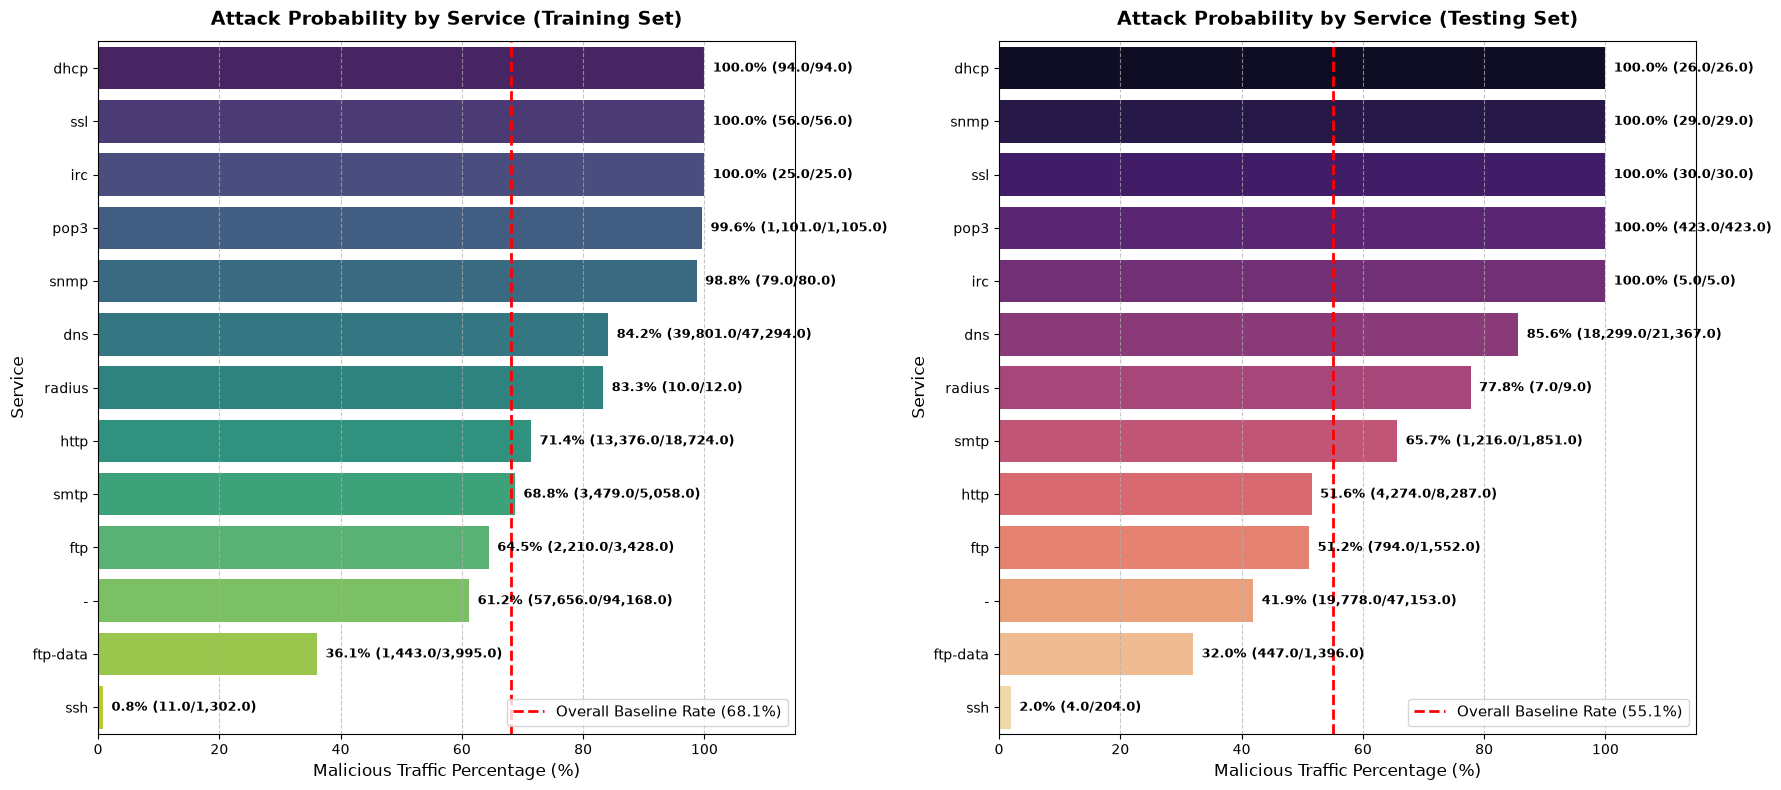

In [21]:
# Create side-by-side bar plots for Training and Testing sets
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for idx, (df, name, ax, palette) in enumerate([
    (df_train, 'Training Set', axes[0], 'viridis'),
    (df_test, 'Testing Set', axes[1], 'magma')
]):
    # Calculate total connections, attack count, and attack percentage per service
    svc_stats = df.groupby('service').agg(
        total=('label', 'count'),
        attacks=('label', 'sum')
    )
    svc_stats['attack_pct'] = (svc_stats['attacks'] / svc_stats['total']) * 100
    
    # Sort services by attack percentage descending
    svc_stats = svc_stats.sort_values(by='attack_pct', ascending=False)
    
    # Overall baseline attack rate for reference
    baseline = df['label'].mean() * 100
    
    # Plot attack percentage per service
    sns.barplot(
        y=svc_stats.index,
        x=svc_stats['attack_pct'],
        ax=ax,
        palette=palette,
        hue=svc_stats.index,
        legend=False
    )
    
    # Add vertical line for overall dataset baseline attack rate
    ax.axvline(baseline, color='red', linestyle='--', linewidth=2, 
               label=f'Overall Baseline Rate ({baseline:.1f}%)')
    
    ax.set_title(f'Attack Probability by Service ({name})', fontsize=14, pad=12, fontweight='bold')
    ax.set_xlabel('Malicious Traffic Percentage (%)', fontsize=12)
    ax.set_ylabel('Service', fontsize=12)
    ax.set_xlim(0, 115)
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    ax.legend(loc='lower right', fontsize=11)
    
    # Annotate percentage and sample size (Attacks / Total) on each bar
    for i, p in enumerate(ax.patches):
        width = p.get_width()
        total_n = svc_stats.iloc[i]['total']
        attack_n = svc_stats.iloc[i]['attacks']
        ax.annotate(f"{width:.1f}% ({attack_n:,}/{total_n:,})",
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(6, 0),
                    textcoords='offset points',
                    fontsize=9,
                    fontweight='bold')

plt.tight_layout()
plt.show()


### **6) Which features are actually useful for prediction?**

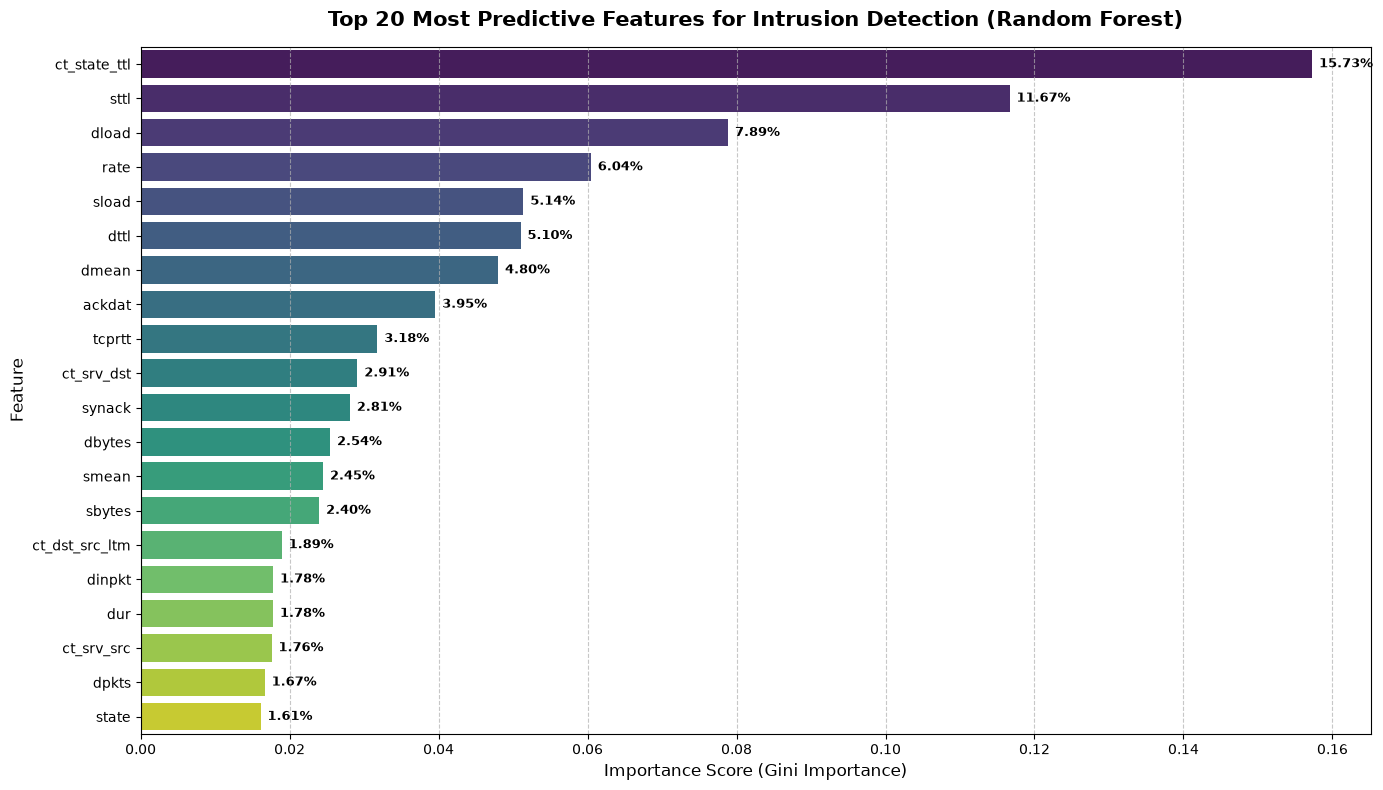

Top 10 Most Useful Features:
     Feature  Importance
ct_state_ttl    0.157274
        sttl    0.116660
       dload    0.078863
        rate    0.060445
       sload    0.051383
        dttl    0.051001
       dmean    0.047990
      ackdat    0.039548
      tcprtt    0.031778
  ct_srv_dst    0.029097


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder

# 1. Prepare Feature Matrix (drop id, labels, and leakage)
drop_cols = ['id', 'attack_cat', 'label', 'traffic_type']
X_train = df_train.drop(columns=[col for col in drop_cols if col in df_train.columns])
y_train = df_train['label']

# 2. Encode categorical features
cat_cols = ['proto', 'service', 'state']
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_enc = X_train.copy()
X_train_enc[cat_cols] = encoder.fit_transform(X_train[cat_cols])

# 3. Fit Random Forest to extract Feature Importance
rf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train_enc, y_train)

# 4. Create Feature Importance DataFrame
feat_importance = pd.DataFrame({
    'Feature': X_train_enc.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

# 5. Plot Top 20 Features
plt.figure(figsize=(14, 8))
sns.barplot(
    x='Importance',
    y='Feature',
    data=feat_importance.head(20),
    palette='viridis',
    hue='Feature',
    legend=False
)
plt.title('Top 20 Most Predictive Features for Intrusion Detection (Random Forest)', 
          fontsize=15, pad=15, fontweight='bold')
plt.xlabel('Importance Score (Gini Importance)', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Annotate percentage contribution on each bar
for p in plt.gca().patches:
    width = p.get_width()
    if width > 0:
        plt.gca().annotate(f"{width * 100:.2f}%", 
                           (width, p.get_y() + p.get_height() / 2.),
                           ha='left', va='center', xytext=(5, 0), 
                           textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Print Top 10 Summary
print("Top 10 Most Useful Features:")
print(feat_importance.head(10).to_string(index=False))
